# 283: Do BHF's kmerseek wins come from its low-complexity stretches?

[Notebook 256](256_bhf_dipeptide_shuffle_null.ipynb)
([PR 83](https://github.com/seanome/2024-kmerseek-analysis/pull/83)) searched BHF
(*Botryllus* histocompatibility factor, 252 aa) and 300 shuffled copies of it against the
19_732 GENCODE v49 canonical human proteins. A **setting** is one kmerseek alphabet at one
k-mer size, with scaled 1, kmerseek's low-complexity mask on, and the extension of
notebook 241; there are 152. Each copy kept BHF's count of every adjacent residue pair
(a dipeptide shuffle). By E-value, BHF did no better than its copies (it beats 95% of them
in 3 of 61 settings; 3.1 expected by chance). Under the other scores BHF beat 95% of its
copies in more settings than chance predicts (5.3 of 106): tf-idf 27, containment 25,
shared k-mers 23, mean IDF 19. 100 of the 153 winning (score, setting) pairs took their BHF
region from residues 63-105 (the 153 count the E-value and bit score, and the Poisson score
and its p-value, separately; each pair ranks the same):

```text
BHF 63-105  ESQEHLDASTKKTKKKAKKDKRKNKPPKKDSETSKPAQTTISR   (15 of 43 residues K or R)
```

The 100 count any winning region that overlaps 63-105 by one residue or more, and half of
all 1_076 (score, setting) pairs (542) overlap it too, against 65% of the winning ones. So
the overlap alone does not show that the stretch causes the wins. A dipeptide shuffle
breaks such a stretch up. The question is whether BHF still beats copies that keep its
low-complexity stretches whole, and whether BHF without them beats its own shuffles.

**Decision this informs.** Whether any kmerseek score shows a BHF signal that is not
low-complexity sequence. If none does, BHF's kmerseek hits are not evidence of homology
to any human protein at any setting, and the paper cannot use them as such.

**Data.** Query: BHF and its copies. Target database: 19_732 GENCODE v49 canonical human
proteins. kmerseek 0.4.0 at commit 982a055, the build of notebooks 241, 242 and 256; the
152 settings, indexes (rebuilt with notebook 241's driver, section 3) and search flags of
notebooks 241 and 256. Run on Sherlock with `283_bhf_low_complexity_control.sbatch`.

**Low-complexity stretches.** The union of every rule that calls part of BHF
low-complexity: kmerseek's own mask at any of the 152 settings, NCBI SEG, and the region
behind notebook 256's wins (section 1).

**Three sets of 300 copies.**
1. Null 1, notebook 256's copies: the whole of BHF dipeptide-shuffled.
2. Null 2, stretches kept: every stretch stays verbatim at its own position; each segment
   between stretches is dipeptide-shuffled on its own.
3. Null 3, stretches removed: the stretches are cut out of BHF, and BHF without them
   (190 aa) is compared with 300 dipeptide shuffles of itself.

BHF "beats 95% of its copies" at a setting when (1 + copies whose best human hit scores
at least as well as BHF's best) / 301 is at most 0.05. By chance that happens in 5% of the
settings where BHF has the score, and sometimes more: if the settings were independent, 6
or more of 106 would happen by chance with probability 0.44, and 11 or more (the decision
line below) with probability 0.017 for one score. Settings of one alphabet see the same
sequence and are not independent, so the real chance spread is wider.

**Predictions, written before the searches ran (2026-10-13).**
- If the non-E-value wins come from the stretches, then under null 2 the number of
  settings where BHF beats 95% of its copies falls to near chance (about 5.3 of 106) for
  every score.
- Under null 3, BHF without its stretches beats its copies no more often than chance.
- The E-value stays at chance under all three nulls.

**Decision rule, written before the searches ran.** If no score beats null 2 in more than
twice the settings chance predicts (10%), the verdict is "BHF: no kmerseek signal beyond
its low-complexity stretches". Otherwise, name the score, the settings and the BHF
region, and show the aligned residues of the top human hit for each. Null 3 is read
against the same 10% line: a score above it means BHF without its stretches still beats
its own shuffles (this sentence added 2026-10-13, also before any search).

In [1]:
import json
import sys
from pathlib import Path

import polars as pl

sys.path.insert(0, str(Path.cwd()))
import bhf_low_complexity_utils as lc
import bhf_shuffle_null_utils as su

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_width_chars(240)
pl.Config.set_fmt_str_lengths(80)
FIG = Path.cwd().parent / "figures"

su.RUN = lc.NULLS["null 1: whole protein shuffled (notebook 256)"]
BHF = su.bhf_sequence()
print(f"BHF: {len(BHF)} aa")
status = {name: lc.run_finished(run) for name, run in lc.NULLS.items()}
for name, (done, total) in status.items():
    print(f"{name}: {done} of {total} search tables")
ALL_DONE = all(d == t for d, t in status.values())

BHF: 252 aa
null 1: whole protein shuffled (notebook 256): 548 of 548 search tables
null 2: stretches kept in place: 0 of 1 search tables
null 3: stretches removed: 0 of 1 search tables


## 1. BHF's low-complexity stretches

kmerseek's mask (`--remove-low-complexity`, on for every index of notebooks 241 and 256)
is not SEG. At 982a055 it drops a k-mer when its k residues are all one amino acid, or,
for every alphabet except protein20 and dayhoff6, when its k letters are all one class of
the alphabet (`src/rust/sketch.rs`, `src/rust/kmer.rs`). A stretch is a run of residues
covered by dropped k-mers, so it depends on the setting. The class tables are read from
kmerseek's `alphabets.rs`, and the count of dropped windows is checked against the count
the kmerseek binary prints when it indexes BHF alone, at every setting.

masked BHF windows, this code vs the kmerseek binary: equal at 152 of 152 settings
settings where kmerseek's mask finds any stretch in BHF: 9 of 152
shape: (9, 5)
┌──────────────────────┬─────┬────────────────┬──────────────────┬────────────────────────────────┐
│ alphabet             ┆ k   ┆ masked_windows ┆ stretches_1based ┆ residues                       │
│ ---                  ┆ --- ┆ ---            ┆ ---              ┆ ---                            │
│ str                  ┆ i64 ┆ i64            ┆ str              ┆ str                            │
╞══════════════════════╪═════╪════════════════╪══════════════════╪════════════════════════════════╡
│ gbmr4                ┆ 10  ┆ 11             ┆ 69-87, 108-117   ┆ DASTKKTKKKAKKDKRKNK SNRNNNNANS │
│ gbmr4                ┆ 13  ┆ 7              ┆ 69-87            ┆ DASTKKTKKKAKKDKRKNK            │
│ gbmr4                ┆ 16  ┆ 4              ┆ 69-87            ┆ DASTKKTKKKAKKDKRKNK            │
│ gbmr4                ┆ 18  ┆ 2     


notebook 256's winning (score, setting) pairs: 153; at a setting where kmerseek's mask finds a stretch: 2


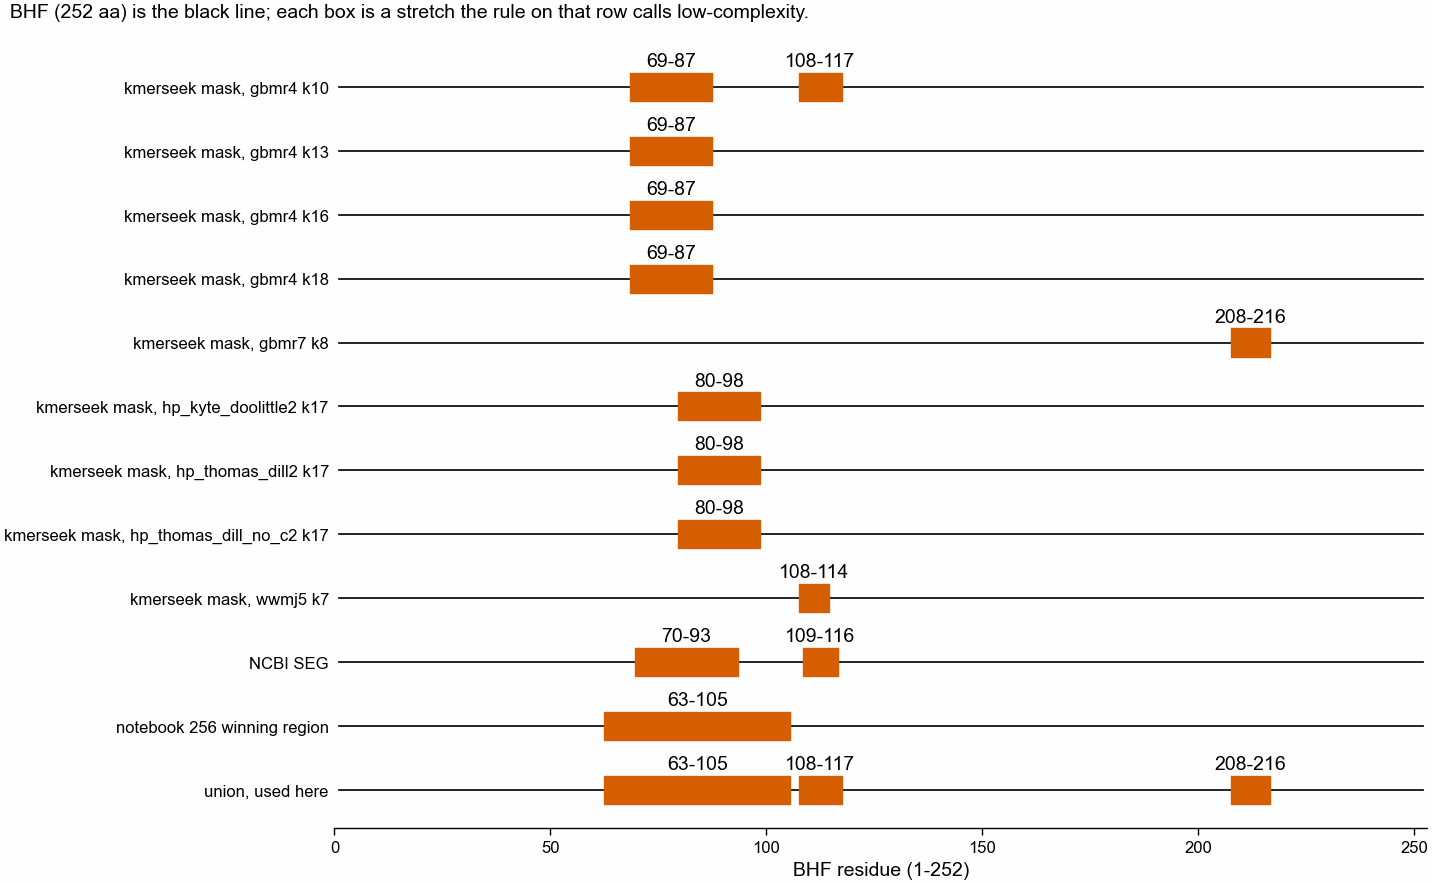

In [2]:
arms = json.loads((su.RUN / "arms.json").read_text())
check = [
    (a["alphabet"], a["k"], *lc.check_against_binary(BHF, a["alphabet"], a["k"]))
    for a in arms
]
n_agree = sum(here == binary for _, _, here, binary in check)
print(
    f"masked BHF windows, this code vs the kmerseek binary: equal at {n_agree} of {len(check)} settings"
)
masked = pl.DataFrame(
    [
        {
            "alphabet": a,
            "k": k,
            "masked_windows": n,
            "stretches_1based": ", ".join(
                f"{s + 1}-{e}" for s, e in lc.stretches(BHF, a, k)
            ),
            "residues": " ".join(BHF[s:e] for s, e in lc.stretches(BHF, a, k)),
        }
        for a, k, n, _ in check
        if n > 0
    ]
).sort("alphabet", "k")
print(
    f"settings where kmerseek's mask finds any stretch in BHF: {masked.height} of {len(check)}"
)
print(masked)

seg = [
    (69, 93),
    (108, 116),
]  # segmasker (BLAST+ 2.16.0) -outfmt interval: 69 - 92, 108 - 115
region_256 = [(62, 105)]
import importlib.util

spec = importlib.util.spec_from_file_location(
    "nb283", "283_bhf_low_complexity_control.py"
)
nb283 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(nb283)
union = nb283.stretch_union(BHF)
print("\nNCBI SEG (segmasker, BLAST+ 2.16.0, defaults):")
for s, e in seg:
    print(f"  {s + 1}-{e}  {BHF[s:e]}")
print("union of all rules, used for nulls 2 and 3:")
for s, e in union:
    print(
        f"  {s + 1}-{e}  {BHF[s:e]}  ({e - s} aa, {sum(c in 'KR' for c in BHF[s:e])} K or R)"
    )
print(f"residues in stretches: {sum(e - s for s, e in union)} of {len(BHF)}")

bp1 = su.best_score_p(su.load())
wins1 = bp1.filter(pl.col("p") <= lc.ALPHA)
lc_settings = set(zip(masked["alphabet"], masked["k"]))
print(
    f"\nnotebook 256's winning (score, setting) pairs: {wins1.height}; "
    f"at a setting where kmerseek's mask finds a stretch: "
    f"{sum((a, k) in lc_settings for a, k in zip(wins1['alphabet'], wins1['k']))}"
)

rows = [
    (f"kmerseek mask, {a} k{k}", lc.stretches(BHF, a, k))
    for a, k in zip(masked["alphabet"], masked["k"])
]
rows += [
    ("NCBI SEG", seg),
    ("notebook 256 winning region", region_256),
    ("union, used here", union),
]
_ = lc.fig_stretches(BHF, rows, FIG / "283_bhf_low_complexity_stretches_kmerseek_seg")

kmerseek's own mask finds a stretch in BHF at only 9 of the 152 settings, and only 2 of
notebook 256's 153 winning (score, setting) pairs are at one of them (both gbmr4 k18). So
at the settings of 151 of the 153 wins, kmerseek's mask, which was on during notebook
256's searches, removed nothing from BHF. Whether the wins come from 63-105 is what
sections 4 and 5 test. SEG calls 70-93 and 109-116 low-complexity, inside 256's region
63-105 but shorter. The copies below use the union: 63-105, 108-117 and 208-216, 62 of 252 residues.

## 2. The three sets of copies

Each null-2 copy keeps the 62 stretch residues in place, so it matches BHF at those
positions by construction. Null-3 copies are shuffles of BHF without its stretches.

shape: (3, 6)
┌───────────────────────────────────────────────┬──────────┬───────────┬──────────────────────┬──────┬──────┐
│ null                                          ┆ n_copies ┆ length_aa ┆ median_pct_identical ┆ min  ┆ max  │
│ ---                                           ┆ ---      ┆ ---       ┆ ---                  ┆ ---  ┆ ---  │
│ str                                           ┆ u32      ┆ i64       ┆ f64                  ┆ f64  ┆ f64  │
╞═══════════════════════════════════════════════╪══════════╪═══════════╪══════════════════════╪══════╪══════╡
│ null 1: whole protein shuffled (notebook 256) ┆ 300      ┆ 252       ┆ 7.1                  ┆ 3.2  ┆ 12.3 │
│ null 2: stretches kept in place               ┆ 300      ┆ 252       ┆ 35.7                 ┆ 30.2 ┆ 41.7 │
│ null 3: stretches removed                     ┆ 300      ┆ 190       ┆ 7.4                  ┆ 2.6  ┆ 14.2 │
└───────────────────────────────────────────────┴──────────┴───────────┴──────────────────────┴──────┴────

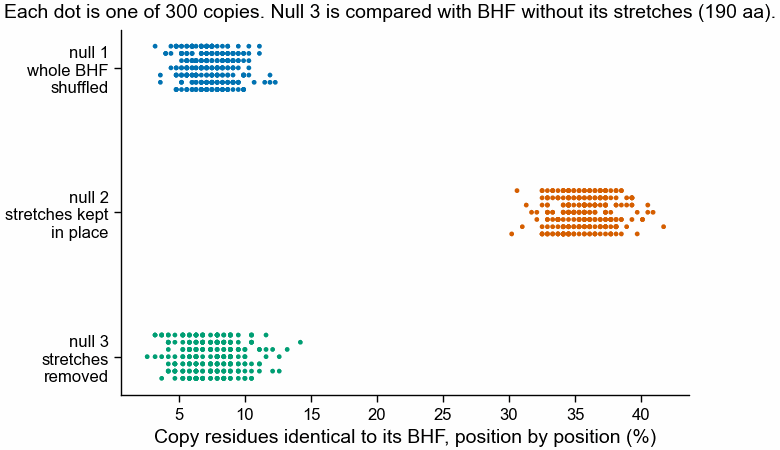

In [3]:
qs = {
    name: (
        nb283.read_fasta(run / "queries.fa") if (run / "queries.fa").exists() else None
    )
    for name, run in lc.NULLS.items()
}
if qs["null 2: stretches kept in place"] is None:
    qs["null 2: stretches kept in place"] = nb283.make_queries("kept", 300, 283)
    qs["null 3: stretches removed"] = nb283.make_queries("removed", 300, 283)
rows = []
for name, q in qs.items():
    ref = q[0][1]
    for h, s in q[1:]:
        rows.append(
            {
                "null": name,
                "copy": h,
                "length_aa": len(s),
                "pct_identical_to_its_BHF": round(
                    100 * sum(a == b for a, b in zip(ref, s)) / len(ref), 1
                ),
            }
        )
ident = pl.DataFrame(rows)
print(
    ident.group_by("null", maintain_order=True).agg(
        pl.len().alias("n_copies"),
        pl.col("length_aa").first().alias("length_aa"),
        pl.col("pct_identical_to_its_BHF").median().alias("median_pct_identical"),
        pl.col("pct_identical_to_its_BHF").min().alias("min"),
        pl.col("pct_identical_to_its_BHF").max().alias("max"),
    )
)
mark = "".join(
    "^" if any(s <= i < e for s, e in union) else " " for i in range(len(BHF))
)
print("\nBHF, one null-2 copy, and the stretches (^), 60 residues per line:")
k1 = qs["null 2: stretches kept in place"][1][1]
for i in range(0, len(BHF), 60):
    print(
        f"{i + 1:>4} BHF      {BHF[i:i + 60]}\n     kept000  {k1[i:i + 60]}\n              {mark[i:i + 60]}"
    )

import matplotlib.pyplot as plt
import pubfig as pf

pf.use_style()
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
cols = [pf.OKABE_ITO["blue"], pf.OKABE_ITO["vermillion"], pf.OKABE_ITO["bluish_green"]]
for j, (name, c) in enumerate(zip(qs, cols)):
    v = ident.filter(pl.col("null") == name)["pct_identical_to_its_BHF"].to_numpy()
    ax.scatter(
        v,
        j + (pl.Series(range(len(v))).to_numpy() % 7 - 3) * 0.05,
        s=3,
        color=c,
        edgecolor="none",
    )
ax.set_yticks(
    range(3),
    [
        "null 1\nwhole BHF\nshuffled",
        "null 2\nstretches kept\nin place",
        "null 3\nstretches\nremoved",
    ],
)
ax.invert_yaxis()
ax.set_xlabel("Copy residues identical to its BHF, position by position (%)")
fig.text(
    0.01,
    1.0,
    "Each dot is one of 300 copies. Null 3 is compared with BHF without its stretches (190 aa).",
    ha="left",
    va="bottom",
)
pf.save(fig, str(FIG / "283_copies_identity_to_bhf_three_nulls"))

## 3. The rebuilt indexes give notebook 256's numbers back

Notebook 241's indexes were deleted from the laptop on 2 October and never copied to
Sherlock. `283_bhf_low_complexity_control.py indexes` rebuilds all 152 with notebook 241's
own driver (same kmerseek build, human FASTA, flags, Karlin-Altschul fit and retry). Before
the new copies are searched, it searches 256's own 301 queries again on 6 settings and stops
unless every best value, and every column of the 9 scores other than the E-value and bit
score, matches the tables notebook 256 stored. The cell below prints that comparison once
the run is copied back.

In [4]:
rep = lc.DATA / "283" / "reproduce_null1" / "reproduce.json"
if rep.exists():
    r = json.loads(rep.read_text())
    print(
        f"rows compared with notebook 256: {r['n_rows']:_}; real differences: {len(r['differ'])}; "
        f"E-value or bit score rows whose top 10 differ: {r['n_top10_differ_evalue_bits']}, "
        f"whose tie count differs: {r['n_tied_differ_evalue_bits']} (near-equal paralogs; see the script)"
    )
else:
    print("the Sherlock run has not been copied back yet")

the Sherlock run has not been copied back yet


## 4. BHF against each set of copies

For each score, the settings where BHF beats 95% of its copies, as a share of the settings
where BHF has that score, under each null. The grey line is chance (5%); the dashed line is
the decision line (10%, twice chance). A score whose null-2 point sits right of the dashed
line has a BHF signal that the stretches do not explain.

In [5]:
if ALL_DONE:
    p = lc.best_score_p_all()
    w = lc.wins_by_null(p)
    print(w)
    over = w.filter(
        (pl.col("null") == "null 2: stretches kept in place")
        & (pl.col("n_beats_95pct") > pl.col("twice_chance"))
    )
    lc.fig_wins_by_null(
        w,
        FIG / "283_bhf_beats_copies_by_null_human_gencode",
        hypothesis="if BHF's wins come from its low-complexity stretches, copies that keep the stretches (null 2) "
        "bring every score back to the 5% chance line.",
        conclusion=(
            f"{over.height} of {len(lc.SCORES)} scores beat null 2 in more than twice the settings chance predicts."
        ),
    )
else:
    print("waiting for the Sherlock run:", status)

waiting for the Sherlock run: {'null 1: whole protein shuffled (notebook 256)': (548, 548), 'null 2: stretches kept in place': (0, 1), 'null 3: stretches removed': (0, 1)}


## 5. The decision rule

In [6]:
if ALL_DONE:
    if over.height == 0:
        print("verdict: BHF: no kmerseek signal beyond its low-complexity stretches")
    else:
        print(
            "scores that beat null 2 in more than twice the settings chance predicts:"
        )
        print(over)
        hum = su.human_sequences()
        kept = lc.NULLS["null 2: stretches kept in place"]
        reg = pl.read_parquet(sorted((kept / "regions").glob("*.parquet"))).filter(
            pl.col("query_name") == "BHF"
        )
        won = p.filter(
            (pl.col("null") == "null 2: stretches kept in place")
            & (pl.col("p") <= lc.ALPHA)
            & pl.col("metric").is_in(over["metric"])
        )
        for row in won.sort("metric", "alphabet", "k").iter_rows(named=True):
            hit = reg.filter(
                (pl.col("metric") == row["metric"])
                & (pl.col("alphabet") == row["alphabet"])
                & (pl.col("k") == row["k"])
                & (pl.col("gene") == row["bhf_top_gene"])
            ).row(0, named=True)
            q = BHF[hit["region_start"] : hit["region_end"]]
            t = hum[hit["gene"]][hit["target_start"] : hit["target_end"]]
            print(
                f"\n{row['metric']}, {row['alphabet']} k{row['k']}: p = {row['p']:.3f}, "
                f"BHF's top human protein {row['bhf_top_gene']} (tied with {row['bhf_n_tied'] - 1} others)"
            )
            print(
                lc.show_alignment(
                    q,
                    hit["region_start"],
                    t,
                    hit["target_start"],
                    hit["gene"],
                    row["alphabet"],
                )
            )